Second part of the work session. Yesterday I collected the imagery, today I want to know if it is
any good. The indicators that need the LCNN and the vanishing point detector are left as `None` for
now, those are the expensive ones.

In [1]:
import json
from pathlib import Path
from typing import Any

import numpy as np
from PIL import Image
from tqdm import tqdm

import imageable._utils.image_quality.image_quality_operations as imqual
from imageable._models.huggingface.floor_sky_ratio_calculator import FloorSkyRatioCalculator
from imageable._models.huggingface.segformer_segmentation import SegformerSegmentationWrapper
from imageable.visualization.data_visualization import plot_grouped_distribution_bars, plot_styled_histogram

/Users/legariapena.j/Documents/imageable-2026/imageable/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


/Users/legariapena.j/Documents/imageable-2026/imageable/.venv/lib/python3.13/site-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)


In [2]:
class QualityMetrics:

    def __init__(
            self,
            entropy:float | None = None,
            sharpness:float | None = None,
            refinement_success:bool | None = None,
            n_lines: int | None = None,
            scores: list[float] | None = None,
            vanishing_points:list[Any] | None = None,
            sky_ratio:float | None = None,
            ground_ratio:float | None = None,
            facade_ratio:float | None = None)->None:

        self.entropy = entropy
        self.sharpness = sharpness
        self.refinement_success = refinement_success
        self.n_lines = n_lines
        self.scores = scores
        self.vanishing_points = vanishing_points
        self.sky_ratio = sky_ratio
        self.ground_ratio = ground_ratio
        self.facade_ratio = facade_ratio

    def as_dict(self):
        quality_dictionary = {}
        quality_dictionary["entropy"] = self.entropy
        quality_dictionary["sharpness"] = self.sharpness
        quality_dictionary["refinement_success"] = self.refinement_success
        quality_dictionary["n_lines"] = self.n_lines
        quality_dictionary["scores"] = self.scores
        quality_dictionary["vanishing_points"] = self.vanishing_points
        quality_dictionary["sky_ratio"] = self.sky_ratio
        quality_dictionary["ground_ratio"] = self.ground_ratio
        quality_dictionary["facade_ratio"] = self.facade_ratio
        return quality_dictionary

In [3]:
DATA_PATH = Path("/Users/legariapena.j/Documents/open-sensing-analysis/open-sensing-analysis/"
"data/2026_08_03_imagery_quality_assessment")

IMAGEABLE_PATH = Path("/Users/legariapena.j/Documents/imageable-2026/imageable")

PARENT_IMAGES = DATA_PATH/Path("images")
QUALITY_METRICS_PATH = DATA_PATH/Path("quality_metrics.json")
PLOTS_PATH = DATA_PATH/Path("quality_plots")
PLOTS_PATH.mkdir(parents = True, exist_ok = True)

n_buildings = len(list(PARENT_IMAGES.glob("building_*")))
print(f"There are {n_buildings} building folders")

image_paths = []
metadata_paths = []

for i in range(0,n_buildings):
    building_folder = PARENT_IMAGES/Path("building_"+str(i))
    image_paths.append(building_folder/Path("image.jpg"))
    metadata_paths.append(building_folder/Path("metadata.json"))

n_missing_images = 0
for i in range(0,len(image_paths)):
    if(not image_paths[i].exists()):
        n_missing_images += 1

print(f"{n_missing_images} of them have no image")

There are 2456 building folders
8 of them have no image


### Models

Same setup as experiment 3 of the framework.

In [4]:
model_sky_ground = FloorSkyRatioCalculator(device = "mps")
model_sky_ground.load_model()

model_facade = SegformerSegmentationWrapper(
    model_name = "nvidia/segformer-b5-finetuned-ade-640-640",
    device = "mps",
    palette_path = str(IMAGEABLE_PATH/"src"/"imageable"/"assets"/"ade20k_palette.json")
)
model_facade.load_model()

print(f"Sky and ground model loaded: {model_sky_ground.is_loaded()}")
print(f"Facade model loaded: {model_facade.is_loaded()}")

The image processor of type `SegformerImageProcessor` is now loaded as a fast processor by default, even if the model checkpoint was saved with a slow processor. This is a breaking change and may produce slightly different outputs. To continue using the slow processor, instantiate this class with `use_fast=False`. 



Loading weights:   0%|          | 0/1172 [00:00<?, ?it/s]


Loading weights:   0%|          | 1/1172 [00:00<00:00, 7423.55it/s, Materializing param=decode_head.batch_norm.bias]


Loading weights:   0%|          | 1/1172 [00:00<00:02, 570.19it/s, Materializing param=decode_head.batch_norm.bias] 


Loading weights:   0%|          | 2/1172 [00:00<00:01, 775.86it/s, Materializing param=decode_head.batch_norm.num_batches_tracked]


Loading weights:   0%|          | 2/1172 [00:00<00:01, 631.72it/s, Materializing param=decode_head.batch_norm.num_batches_tracked]

... (2,343 outputs left out)


Loading weights: 100%|██████████| 1172/1172 [00:00<00:00, 1709.26it/s, Materializing param=segformer.encoder.patch_embeddings.3.proj.weight]


Loading weights: 100%|██████████| 1172/1172 [00:00<00:00, 1709.26it/s, Materializing param=segformer.encoder.patch_embeddings.3.proj.weight]


Loading weights: 100%|██████████| 1172/1172 [00:00<00:00, 1744.70it/s, Materializing param=segformer.encoder.patch_embeddings.3.proj.weight]

Sky and ground model loaded: True
Facade model loaded: True


### Quality assessment of the images collected in part 1

In [5]:
quality_metrics = []

for i in tqdm(range(0,len(image_paths))):
    image_path = image_paths[i]
    metadata_path = metadata_paths[i]

    if(not image_path.exists()):
        quality_metrics.append(QualityMetrics())
        continue

    img = np.array(Image.open(image_path).convert("RGB"))

    entropy = imqual.get_image_entropy(img)
    sharpness = imqual.get_sharpness(img)
    sky_ratio, ground_ratio = imqual.get_sky_and_ground_ratios(img, model_sky_ground)
    facade_ratio = imqual.get_facade_ratio(img, model_facade)

    refinement_success = None
    if(metadata_path.exists()):
        with metadata_path.open("r") as file:
            metadata = json.load(file)

        refinement_success = imqual.get_refinement_success(metadata)

    quality_object = QualityMetrics(
        entropy = entropy,
        sharpness = sharpness,
        refinement_success = refinement_success,
        sky_ratio = sky_ratio,
        ground_ratio = ground_ratio,
        facade_ratio = facade_ratio
    )

    quality_metrics.append(quality_object)

print(f"Collected quality metrics for {len(quality_metrics)} buildings")


  0%|          | 0/2456 [00:00<?, ?it/s]


  0%|          | 1/2456 [00:01<50:00,  1.22s/it]


  0%|          | 2/2456 [00:01<38:07,  1.07it/s]


  0%|          | 3/2456 [00:02<25:51,  1.58it/s]


  0%|          | 4/2456 [00:02<27:35,  1.48it/s]


  0%|          | 5/2456 [00:03<28:31,  1.43it/s]

... (2,441 outputs left out)


100%|█████████▉| 2455/2456 [31:21<00:00,  1.38it/s]


100%|██████████| 2456/2456 [31:22<00:00,  1.24it/s]


100%|██████████| 2456/2456 [31:22<00:00,  1.30it/s]

Collected quality metrics for 2456 buildings


### Export the quality metrics

In [6]:
quality_dictionaries = []

for i in range(0,len(quality_metrics)):
    quality_dictionary = quality_metrics[i].as_dict()
    quality_dictionary["building_index"] = i
    quality_dictionary["image_path"] = str(image_paths[i])
    quality_dictionaries.append(quality_dictionary)

with open(QUALITY_METRICS_PATH, "w") as file:
    json.dump(
        quality_dictionaries,
        file,
        indent = 4,
        default = lambda value: value.item() if isinstance(value, np.generic) else value
    )

print(f"Saved quality metrics to {QUALITY_METRICS_PATH}")

Saved quality metrics to /Users/legariapena.j/Documents/open-sensing-analysis/open-sensing-analysis/data/2026_08_03_imagery_quality_assessment/quality_metrics.json


### Thresholds

The framework has no absolute thresholds. Experiment 3 calls an image low quality when
the attribute is at or below its 10th percentile over the validation images, and above the 90th for the
entropy, so I take those percentiles from there.

In [7]:
FRAMEWORK_METRICS_PATH = IMAGEABLE_PATH/Path("framework-imageable")/Path("results")/Path("preparation_experiment_3.json")

LOW_QUALITY_PERCENTILE = 10
HIGH_QUALITY_PERCENTILE = 90

with open(FRAMEWORK_METRICS_PATH, "r") as file:
    framework_metrics = json.load(file)

print(f"The framework validation set has {len(framework_metrics)} images")

def get_framework_threshold(metric_key, percentile):
    values = []
    for i in range(0,len(framework_metrics)):
        value = framework_metrics[i][metric_key]
        if(value is not None):
            values.append(value)

    return float(np.percentile(values, percentile))

facade_ratio_threshold = get_framework_threshold("facade_ratio", LOW_QUALITY_PERCENTILE)
entropy_threshold = get_framework_threshold("image_entropy", HIGH_QUALITY_PERCENTILE)
sharpness_threshold = get_framework_threshold("sharpness", LOW_QUALITY_PERCENTILE)
sky_ratio_threshold = get_framework_threshold("sky_ratio", LOW_QUALITY_PERCENTILE)
ground_ratio_threshold = get_framework_threshold("ground_ratio", LOW_QUALITY_PERCENTILE)

del framework_metrics

print(f"Facade ratio threshold: {facade_ratio_threshold}")
print(f"Entropy threshold: {entropy_threshold}")
print(f"Sharpness threshold: {sharpness_threshold}")
print(f"Sky ratio threshold: {sky_ratio_threshold}")
print(f"Ground ratio threshold: {ground_ratio_threshold}")

The framework validation set has 3985 images
Facade ratio threshold: 0.08158349609375001
Entropy threshold: 7.816461302743639
Sharpness threshold: 1697.2998832640233
Sky ratio threshold: 0.0
Ground ratio threshold: 0.0


In [8]:
def get_metric_values(quality_metrics, metric_key):
    values = []
    for i in range(0,len(quality_metrics)):
        value = quality_metrics[i].as_dict()[metric_key]
        if(value is not None):
            values.append(value)

    return values

def get_low_quality_percentage(values, threshold, good_side):
    values = np.asarray(values, dtype = float)
    if(good_side == "right"):
        n_low_quality = np.sum(values <= threshold)
    else:
        n_low_quality = np.sum(values > threshold)

    return float(100*n_low_quality/len(values))

### Building visibility

The facade ratio tells me whether the building is actually in the picture.

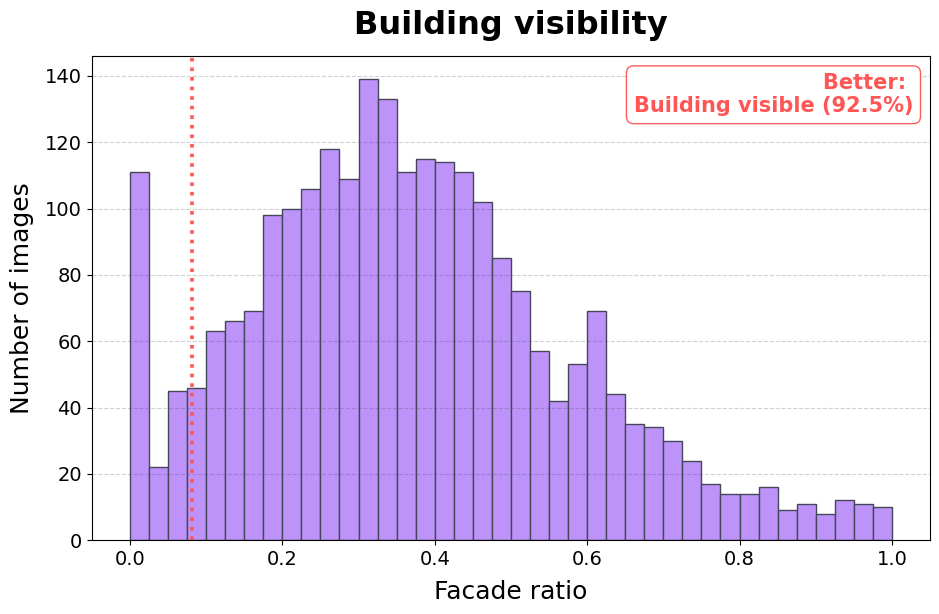

7.5% of the images fall in the low building visibility region


In [9]:
facade_ratios = get_metric_values(quality_metrics, "facade_ratio")

plot_styled_histogram(
    facade_ratios,
    title = "Building visibility",
    x_label = "Facade ratio",
    y_label = "Number of images",
    bins = 40,
    reference_x = facade_ratio_threshold,
    better_right_label = "Building visible",
    savepath = str(PLOTS_PATH/Path("building_visibility.png"))
)

percentage_low_visibility = get_low_quality_percentage(facade_ratios, facade_ratio_threshold, "right")
print(f"{percentage_low_visibility:.1f}% of the images fall in the low building visibility region")

### Camera refinement

`adjustment_success` says if the camera could be moved so that the whole
building fits.

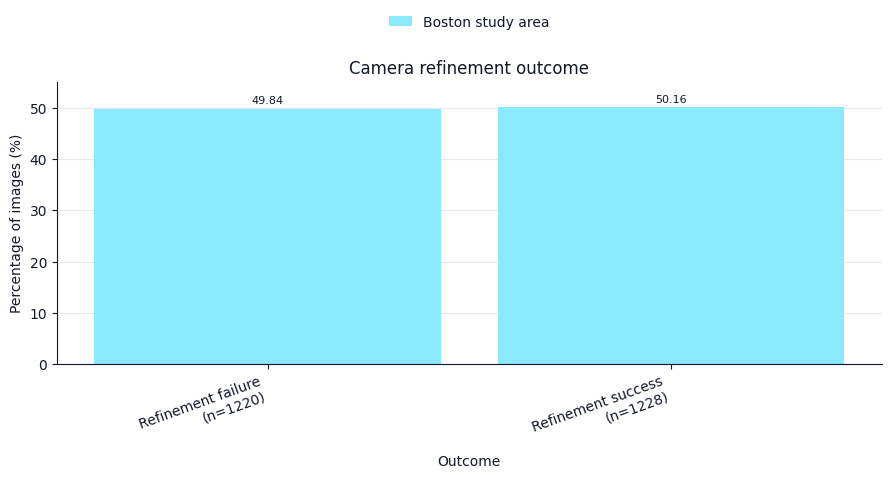

1220 failures and 1228 successes out of 2448 images


In [10]:
refinement_values = get_metric_values(quality_metrics, "refinement_success")

n_success = 0
n_failure = 0

for i in range(0,len(refinement_values)):
    if(refinement_values[i] == True):
        n_success += 1
    else:
        n_failure += 1

percentage_failure = 100*n_failure/len(refinement_values)
percentage_success = 100*n_success/len(refinement_values)

plot_grouped_distribution_bars(
    groups = ["Refinement failure", "Refinement success"],
    model_names = ["Boston study area"],
    rmse = [[percentage_failure, percentage_success]],
    counts = [n_failure, n_success],
    order = "input",
    title = "Camera refinement outcome",
    x_label = "Outcome",
    y_label = "Percentage of images (%)"
)

print(f"{n_failure} failures and {n_success} successes out of {len(refinement_values)} images")

### Imageable framework quality attribute distributions

The sky and the ground thresholds land on
zero because more than ten percent of the framework images have none of either visible.

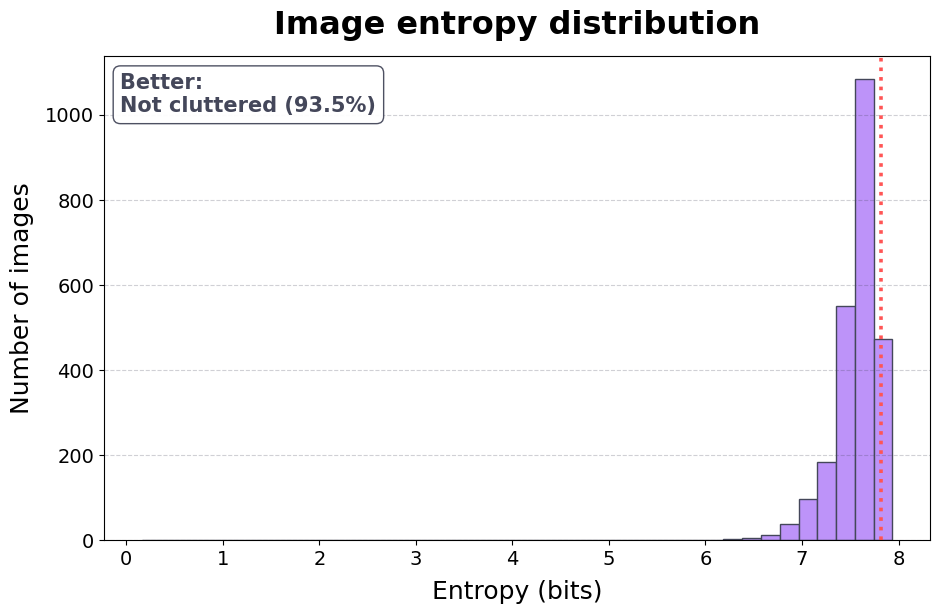

High entropy: 6.5% of the images


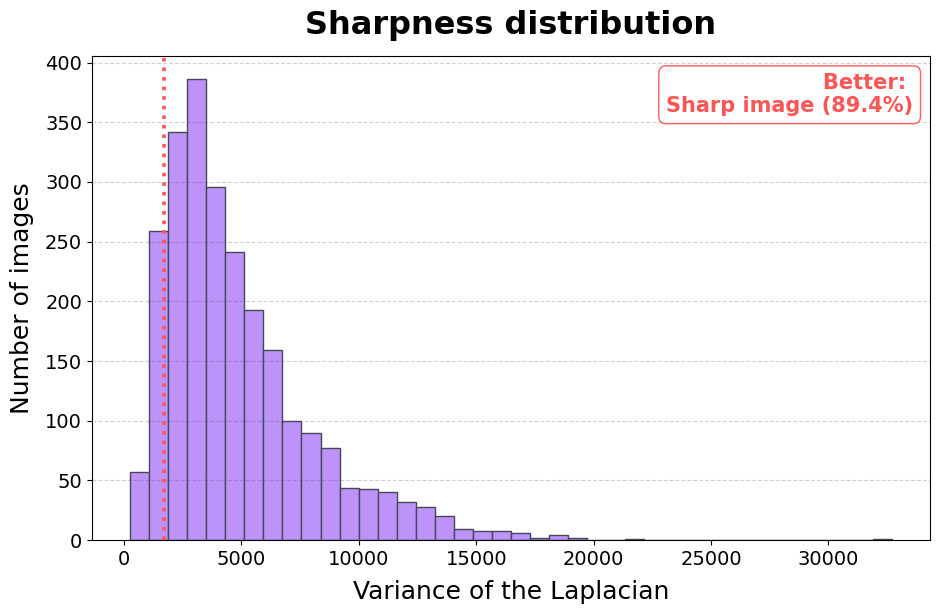

Low sharpness: 10.6% of the images


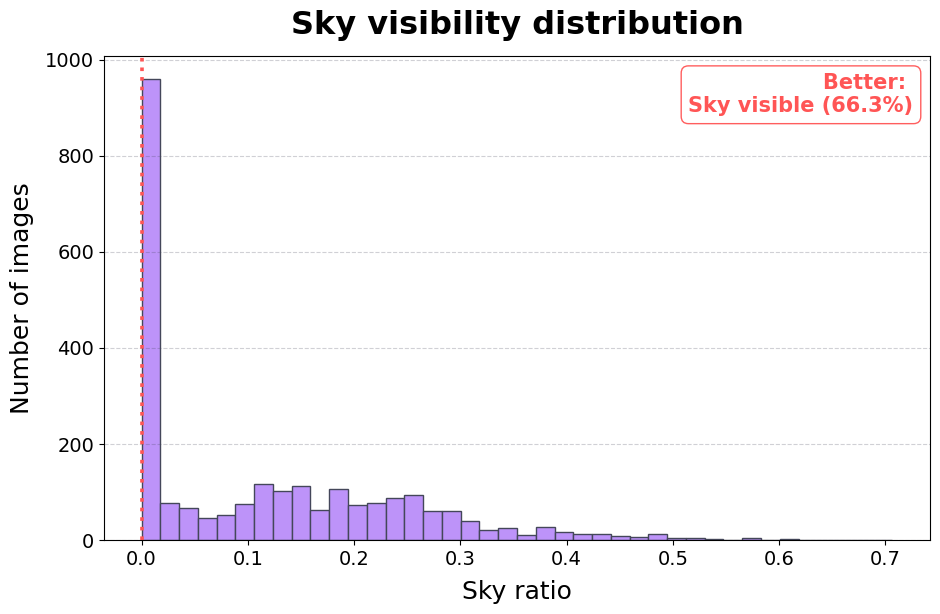

Low sky visibility: 33.7% of the images


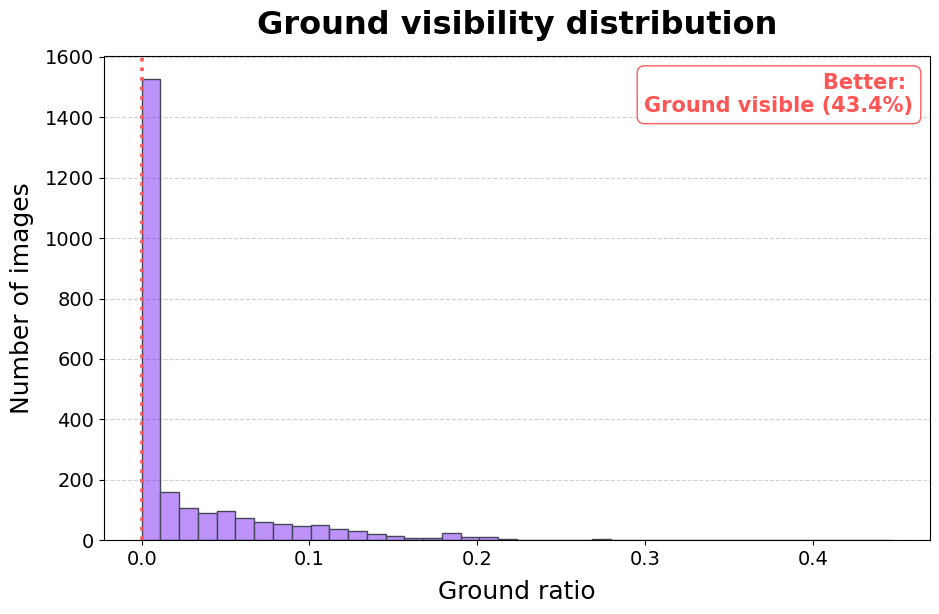

Low ground visibility: 56.6% of the images


In [ ]:
distribution_specs = [
    {
        "name": "High entropy",
        "metric_key": "entropy",
        "title": "Image entropy distribution",
        "x_label": "Entropy (bits)",
        "threshold": entropy_threshold,
        "good_side": "left",
        "good_label": "Not cluttered",
        "file_name": "entropy_distribution.png"
    },
    {
        "name": "Low sharpness",
        "metric_key": "sharpness",
        "title": "Sharpness distribution",
        "x_label": "Variance of the Laplacian",
        "threshold": sharpness_threshold,
        "good_side": "right",
        "good_label": "Sharp image",
        "file_name": "sharpness_distribution.png"
    },
    {
        "name": "Low sky visibility",
        "metric_key": "sky_ratio",
        "title": "Sky visibility distribution",
        "x_label": "Sky ratio",
        "threshold": sky_ratio_threshold,
        "good_side": "right",
        "good_label": "Sky visible",
        "file_name": "sky_visibility_distribution.png"
    },
    {
        "name": "Low ground visibility",
        "metric_key": "ground_ratio",
        "title": "Ground visibility distribution",
        "x_label": "Ground ratio",
        "threshold": ground_ratio_threshold,
        "good_side": "right",
        "good_label": "Ground visible",
        "file_name": "ground_visibility_distribution.png"
    }
]

for i in range(0,len(distribution_specs)):
    spec = distribution_specs[i]
    #We need to get an array with the values to plot the distribution.
    values = get_metric_values(quality_metrics, spec["metric_key"])

    good_label_left = None
    good_label_right = None
    if(spec["good_side"] == "left"):
        good_label_left = spec["good_label"]
    else:
        good_label_right = spec["good_label"]

    plot_styled_histogram(
        values,
        title = spec["title"],
        x_label = spec["x_label"],
        y_label = "Number of images",
        bins = 40,
        reference_x = spec["threshold"],
        better_left_label = good_label_left,
        better_right_label = good_label_right,
        savepath = str(PLOTS_PATH/Path(spec["file_name"]))
    )

    percentage_low_quality = get_low_quality_percentage(values, spec["threshold"], spec["good_side"])
    print(f"{spec['name']}: {percentage_low_quality:.1f}% of the images")

### Quality summary

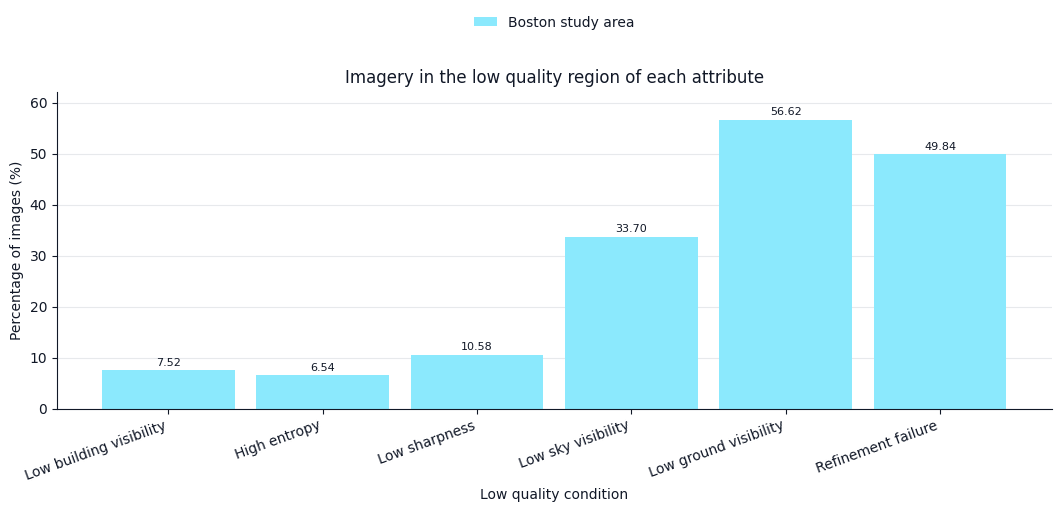

(<Figure size 1050x500 with 1 Axes>,
 <Axes: title={'center': 'Imagery in the low quality region of each attribute'}, xlabel='Low quality condition', ylabel='Percentage of images (%)'>)

In [12]:
summary_names = ["Low building visibility"]
summary_percentages = [get_low_quality_percentage(facade_ratios, facade_ratio_threshold, "right")]

for i in range(0,len(distribution_specs)):
    spec = distribution_specs[i]
    values = get_metric_values(quality_metrics, spec["metric_key"])
    summary_names.append(spec["name"])
    summary_percentages.append(get_low_quality_percentage(values, spec["threshold"], spec["good_side"]))

summary_names.append("Refinement failure")
summary_percentages.append(percentage_failure)

plot_grouped_distribution_bars(
    groups = summary_names,
    model_names = ["Boston study area"],
    rmse = [summary_percentages],
    order = "input",
    title = "Imagery in the low quality region of each attribute",
    x_label = "Low quality condition",
    y_label = "Percentage of images (%)",
    show_n = False,
    figsize = (10.5, 5.0),
    savepath = str(PLOTS_PATH/Path("low_quality_summary.png"))
)